In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [210]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv")
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [4]:
o=[]
n=[]
for i in df.columns:
    if df[i].dtype==object:
        o.append(i)
    else:
        n.append(i)

In [5]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [6]:
df[df.duplicated()]

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager


<Axes: xlabel='Attrition'>

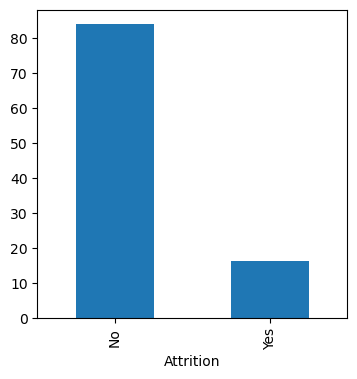

In [7]:
(df["Attrition"].value_counts(normalize=True)*100).plot(kind="bar",figsize=(4,4))

In [8]:
import scipy.stats as ss

In [9]:
category=[]
for i in o:
    if i!= "Attrition":
        ob=pd.crosstab(df[i],df["Attrition"])
        stas,pvalue,_,_=ss.chi2_contingency(ob)
        if pvalue <= 0.05:
            print(i,pvalue)
            category.append(i)


BusinessTravel 5.608614476449931e-06
Department 0.004525606574479633
EducationField 0.006773980139025212
JobRole 2.752481638050657e-15
MaritalStatus 9.45551106034083e-11
OverTime 8.15842372153832e-21


In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif_data=df[n]
total_columns=vif_data.shape[1]

column_kept=[]
column_indx=0

for i in range(0,total_columns):
    vif_value = variance_inflation_factor(vif_data,column_indx)
    print(column_indx ,  vif_value)

    if vif_value <= 6:
        column_kept.append(n[i])
        column_indx+=1
    else:
        vif_data= vif_data.drop(n[i],axis=1)

0 2.04499681178135
1 1.0208630418706492
2 1.0165140650941091
3 1.0612474517881902
4 0.0
5 1.01955778361236
6 1.0105652757998973
7 1.0192124672661609
8 1.0163674890723406
9 11.208730590134236
9 1.0160482954226169
10 2.53892512646844
11 1.0118790094854953
12 1.2571947440467937
13 2.5156243499354596
14 2.5143558714302543
15 1.020232313732649
16 0.0
17 1.0207216253800744
18 4.667623722827323
19 1.0103429709467395
20 1.0135739390138376
21 4.587120726142268
22 2.71727711178552
23 1.6739032771238986
24 2.768279668180491


C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss
C:\Users\megha\anaconda3\Lib\site-packages\statsmodels\regression\linear_model.py:1782: RuntimeWarning: divide by zero encountered in scalar divide
  return 1 - self.ssr/self.centered_tss


In [11]:
numaric_import=[]
for i in column_kept:
    g1=df[df["Attrition"]=="No"][i]
    g2=df[df["Attrition"]=="Yes"][i]
    s,p=ss.f_oneway(g1,g2)
    if p < 0.05:
        print(i,p)
        numaric_import.append(i)
        

Age 8.356308021102401e-10
DailyRate 0.02985816066026101
DistanceFromHome 0.0027930600802132115


C:\Users\megha\anaconda3\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: ConstantInputWarning: Each of the input arrays is constant; the F statistic is not defined or infinite
  res = hypotest_fun_out(*samples, **kwds)


EnvironmentSatisfaction 7.172338549367721e-05
JobInvolvement 5.677065356744583e-07
JobSatisfaction 7.043066741730351e-05
MonthlyIncome 7.147363985353002e-10
StockOptionLevel 1.301014966002024e-07
TotalWorkingYears 4.061878111266676e-11
TrainingTimesLastYear 0.02257849973719727
WorkLifeBalance 0.014211054989019685
YearsAtCompany 2.3188716103859732e-07
YearsInCurrentRole 6.003185843640478e-10
YearsWithCurrManager 1.7369867845240718e-09


In [12]:
df[category]

,BusinessTravel,Department,EducationField,JobRole,MaritalStatus,OverTime
0,Travel_Rarely,Sales,Life Sciences,Sales Executive,Single,Yes
1,Travel_Frequently,Research & Development,Life Sciences,Research Scientist,Married,No
2,Travel_Rarely,Research & Development,Other,Laboratory Technician,Single,Yes
3,Travel_Frequently,Research & Development,Life Sciences,Research Scientist,Married,Yes
4,Travel_Rarely,Research & Development,Medical,Laboratory Technician,Married,No
...,...,...,...,...,...,...
1465,Travel_Frequently,Research & Development,Medical,Laboratory Technician,Married,No
1466,Travel_Rarely,Research & Development,Medical,Healthcare Representative,Married,No
1467,Travel_Rarely,Research & Development,Life Sciences,Manufacturing Director,Married,Yes
1468,Travel_Frequently,Sales,Medical,Sales Executive,Married,No


In [13]:
df1=pd.concat([df[numaric_import],df[category],df["Attrition"]],axis=1)


In [14]:
df1.columns

Index(['Age', 'DailyRate', 'DistanceFromHome', 'EnvironmentSatisfaction',
       'JobInvolvement', 'JobSatisfaction', 'MonthlyIncome',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsWithCurrManager', 'BusinessTravel', 'Department',
       'EducationField', 'JobRole', 'MaritalStatus', 'OverTime', 'Attrition'],
      dtype='object')

# Outlier detaction

In [15]:
# outlier detection using iqr 
for i in numaric_import:
    
    q1=df[i].describe()["25%"]
    q3=df[i].describe()["75%"]
    iqr= q3-q1
    l=q1 - 1.5*iqr
    u=q3 + 1.5*iqr
    out=len(df[(df[i]<l) | (df[i]>u)])
    if out > 0:
        print(i,"--------outlier counts:- ",out)


MonthlyIncome --------outlier counts:-  114
StockOptionLevel --------outlier counts:-  85
TotalWorkingYears --------outlier counts:-  63
TrainingTimesLastYear --------outlier counts:-  238
YearsAtCompany --------outlier counts:-  104
YearsInCurrentRole --------outlier counts:-  21
YearsWithCurrManager --------outlier counts:-  14


# EDA

In [16]:
# bivariate 

In [159]:
# numaric columns

In [17]:
# Age vs Attrition 

<Axes: ylabel='Density'>

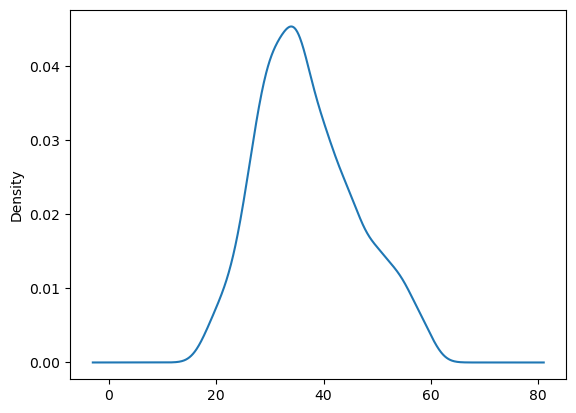

In [18]:
df1["Age"].plot(kind="kde")

In [ ]:
# Attrition VS Age

<Axes: ylabel='Density'>

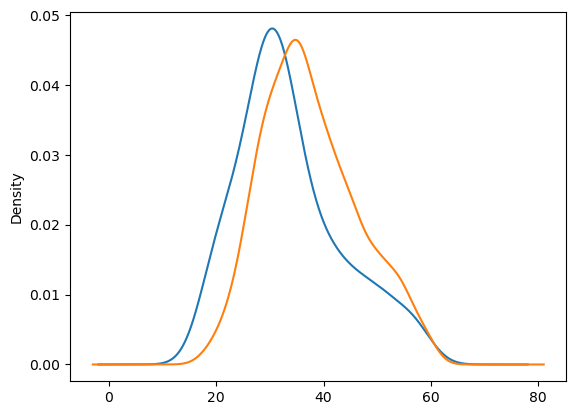

In [19]:
df1[df1["Attrition"]=="Yes"]['Age'].plot(kind="kde")
df1[df1["Attrition"]=="No"]['Age'].plot(kind="kde")

In [33]:
df["Age"].describe()

count    1470.000000
mean       36.923810
std         9.135373
min        18.000000
25%        30.000000
50%        36.000000
75%        43.000000
max        60.000000
Name: Age, dtype: float64

Text(0.5, 0.98, 'Attrition with Age')

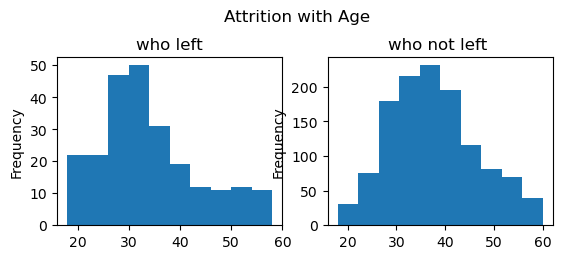

In [29]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]['Age'].plot(kind="hist")
plt.title("who left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]['Age'].plot(kind="hist")
plt.title("who not left ")
plt.suptitle("Attrition with Age")

In [30]:
# Attrition with MontlyIncome

In [31]:
df1["MonthlyIncome"].describe()

count     1470.000000
mean      6502.931293
std       4707.956783
min       1009.000000
25%       2911.000000
50%       4919.000000
75%       8379.000000
max      19999.000000
Name: MonthlyIncome, dtype: float64

<Axes: ylabel='Frequency'>

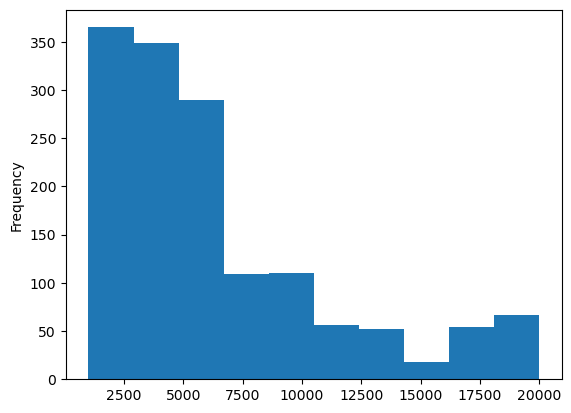

In [38]:
df1["MonthlyIncome"].plot(kind="hist",bins=10)

Attrition :- Yes
mean       4787.092827
median     3202.000000
max       19859.000000
Name: MonthlyIncome, dtype: float64

Attrition :- No
mean       6832.739659
median     5204.000000
max       19999.000000
Name: MonthlyIncome, dtype: float64


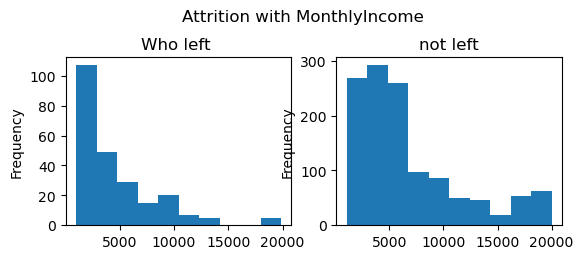

In [44]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["MonthlyIncome"].plot(kind="hist")
plt.title("Who left ")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["MonthlyIncome"].plot(kind="hist")
plt.title("not left")

plt.suptitle("Attrition with MonthlyIncome ")

print("Attrition :- Yes")
print(df1[df1["Attrition"]=="Yes"]["MonthlyIncome"].agg(["mean","median","max"]))
print()
print("Attrition :- No")
print(df1[df1["Attrition"]=="No"]["MonthlyIncome"].agg(["mean","median","max"]))

In [45]:
# Attrition with DistanceFromHome

In [46]:
df["DistanceFromHome"].describe()

count    1470.000000
mean        9.192517
std         8.106864
min         1.000000
25%         2.000000
50%         7.000000
75%        14.000000
max        29.000000
Name: DistanceFromHome, dtype: float64

Attrition :- YES
mean      10.632911
median     9.000000
max       29.000000
Name: DistanceFromHome, dtype: float64

Attrition :- No
mean       8.915653
median     7.000000
max       29.000000
Name: DistanceFromHome, dtype: float64


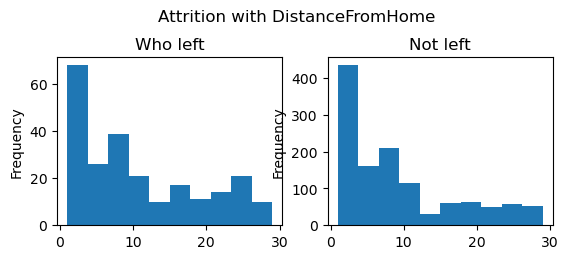

In [52]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["DistanceFromHome"].plot(kind="hist")
plt.title("Who left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["DistanceFromHome"].plot(kind="hist")
plt.title("Not left")

plt.suptitle("Attrition with DistanceFromHome")

print("Attrition :- YES")
print(df1[df1["Attrition"]=="Yes"]["DistanceFromHome"].agg(["mean","median","max"]))
print()
print("Attrition :- No")
print(df1[df1["Attrition"]=="No"]["DistanceFromHome"].agg(["mean","median","max"]))

In [53]:
# Attrition with EnviromentStatisfaction 

In [54]:
df["EnvironmentSatisfaction"].describe()

count    1470.000000
mean        2.721769
std         1.093082
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         4.000000
Name: EnvironmentSatisfaction, dtype: float64

<Axes: xlabel='EnvironmentSatisfaction'>

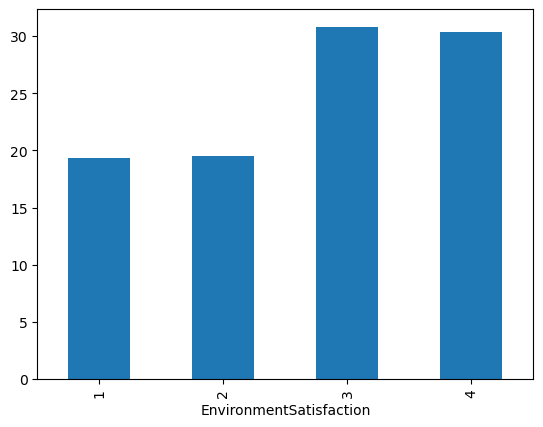

In [96]:
(df["EnvironmentSatisfaction"].value_counts(normalize=True)*100).sort_index().plot(kind="bar")

Attrition :- Yes
mean      2.464135
median    3.000000
max       4.000000
Name: EnvironmentSatisfaction, dtype: float64

Attrition :- No
mean      2.77129
median    3.00000
max       4.00000
Name: EnvironmentSatisfaction, dtype: float64


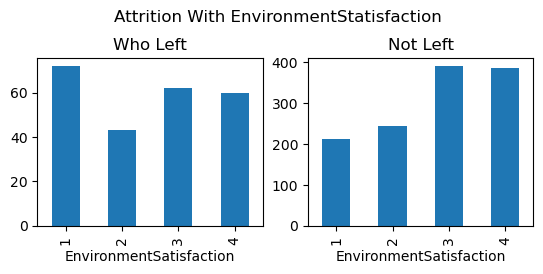

In [95]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["EnvironmentSatisfaction"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["EnvironmentSatisfaction"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With EnvironmentStatisfaction")


print("Attrition :- Yes")
print(df1[df1["Attrition"]=="Yes"]["EnvironmentSatisfaction"].agg(["mean","median","max"]))
print()
print("Attrition :- No")
print(df1[df1["Attrition"]=="No"]["EnvironmentSatisfaction"].agg(["mean","median","max"]))

In [64]:
# Attrition With JobInvolvemnet

In [65]:
df["JobInvolvement"].describe()

count    1470.000000
mean        2.729932
std         0.711561
min         1.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         4.000000
Name: JobInvolvement, dtype: float64

<Axes: xlabel='JobInvolvement'>

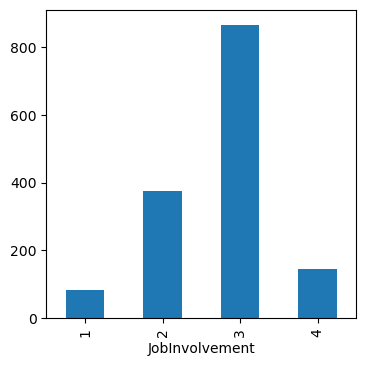

In [94]:

df["JobInvolvement"].value_counts().sort_index().plot(kind="bar",figsize=(4,4))

Attrtion :- YEs
mean      2.518987
median    3.000000
max       4.000000
Name: JobInvolvement, dtype: float64

Attriton :- Yes
mean      2.770479
median    3.000000
max       4.000000
Name: JobInvolvement, dtype: float64


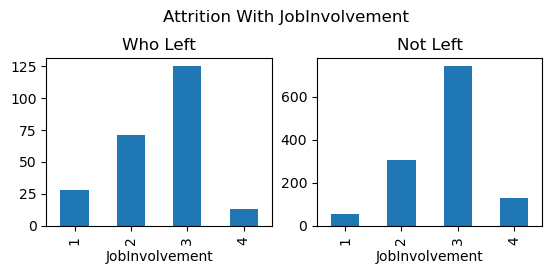

In [93]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["JobInvolvement"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")

plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["JobInvolvement"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With JobInvolvement")

print("Attrtion :- YEs")
print(df1[df1["Attrition"]=="Yes"]["JobInvolvement"].agg(["mean","median","max"]))
print()
print("Attriton :- Yes")
print(df1[df1["Attrition"]=="No"]["JobInvolvement"].agg(["mean","median","max"]))

In [74]:
# Attrirtion With JobStatisfaction

In [75]:
df["JobSatisfaction"].describe()

count    1470.000000
mean        2.728571
std         1.102846
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         4.000000
Name: JobSatisfaction, dtype: float64

<Axes: xlabel='JobSatisfaction'>

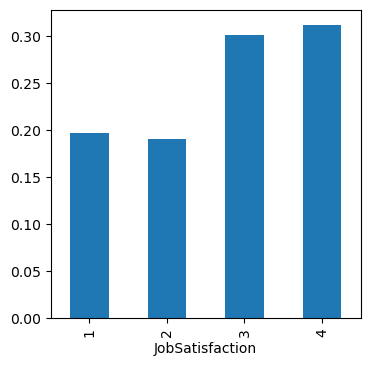

In [92]:
df["JobSatisfaction"].value_counts(normalize=True).sort_index().plot(kind="bar",figsize=(4,4))

               mean  median  max
Attrition                       
No         2.778589     3.0    4
Yes        2.468354     3.0    4


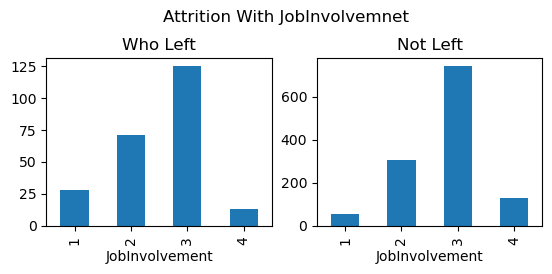

In [91]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["JobInvolvement"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["JobInvolvement"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With JobInvolvemnet")

print(df1.groupby("Attrition")["JobSatisfaction"].agg(["mean","median","max"]))

In [100]:
# Attrition With StockOptionLevel

<Axes: xlabel='StockOptionLevel'>

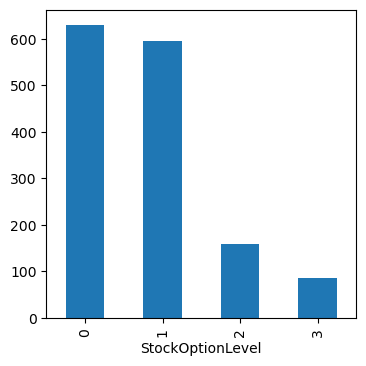

In [89]:
df1["StockOptionLevel"].value_counts().sort_index().plot(kind="bar",figsize=(4,4))

               mean  median  max
Attrition                       
No         0.845093     1.0    3
Yes        0.527426     0.0    3


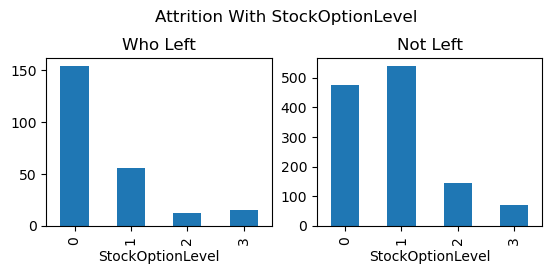

In [98]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["StockOptionLevel"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["StockOptionLevel"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With StockOptionLevel")

print(df1.groupby("Attrition")["StockOptionLevel"].agg(["mean","median","max"]))

In [99]:
# Attrition With TotalWorkingYears

In [113]:
df["TotalWorkingYears"].describe()

count    1470.000000
mean       11.279592
std         7.780782
min         0.000000
25%         6.000000
50%        10.000000
75%        15.000000
max        40.000000
Name: TotalWorkingYears, dtype: float64

<Axes: ylabel='Frequency'>

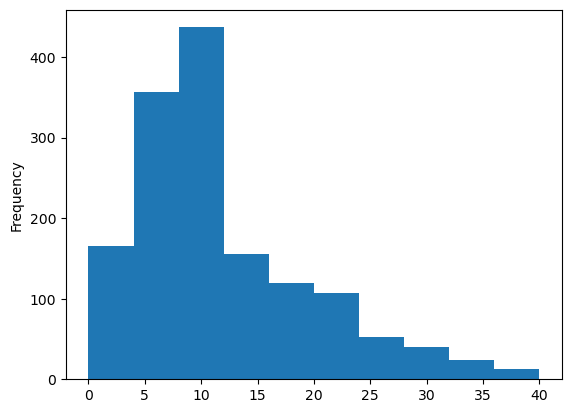

In [158]:
df1["TotalWorkingYears"].plot(kind="hist")

                mean  median  max
Attrition                        
No         11.862936    10.0   38
Yes         8.244726     7.0   40


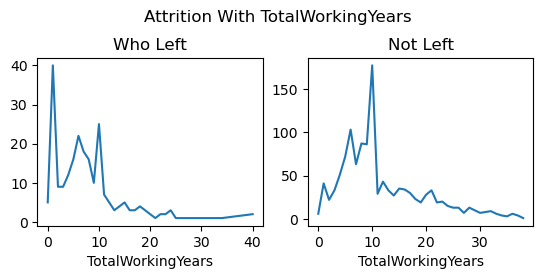

In [122]:

plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["TotalWorkingYears"].value_counts().sort_index().plot(kind="line")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["TotalWorkingYears"].value_counts().sort_index().plot(kind="line")
plt.title("Not Left")
plt.suptitle("Attrition With TotalWorkingYears")

print(df1.groupby("Attrition")["TotalWorkingYears"].agg(["mean","median","max"]))

In [107]:
# Attrition With TrainingTimesLastYear

In [109]:
df["TrainingTimesLastYear"].describe()

count    1470.000000
mean        2.799320
std         1.289271
min         0.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         6.000000
Name: TrainingTimesLastYear, dtype: float64

<Axes: xlabel='TrainingTimesLastYear'>

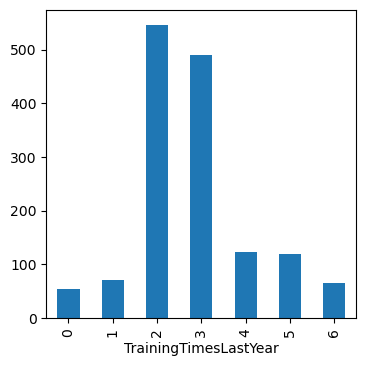

In [110]:
df1["TrainingTimesLastYear"].value_counts().sort_index().plot(kind="bar",figsize=(4,4))

               mean  median  max
Attrition                       
No         2.832928     3.0    6
Yes        2.624473     2.0    6


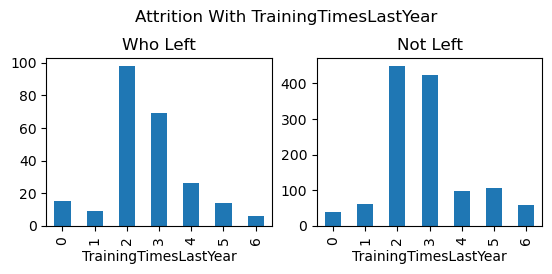

In [111]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["TrainingTimesLastYear"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["TrainingTimesLastYear"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With TrainingTimesLastYear")

print(df1.groupby("Attrition")["TrainingTimesLastYear"].agg(["mean","median","max"]))

In [123]:
# Attrition With WorklifeBalance

In [126]:
df1["WorkLifeBalance"].describe()

count    1470.000000
mean        2.761224
std         0.706476
min         1.000000
25%         2.000000
50%         3.000000
75%         3.000000
max         4.000000
Name: WorkLifeBalance, dtype: float64

<Axes: xlabel='WorkLifeBalance'>

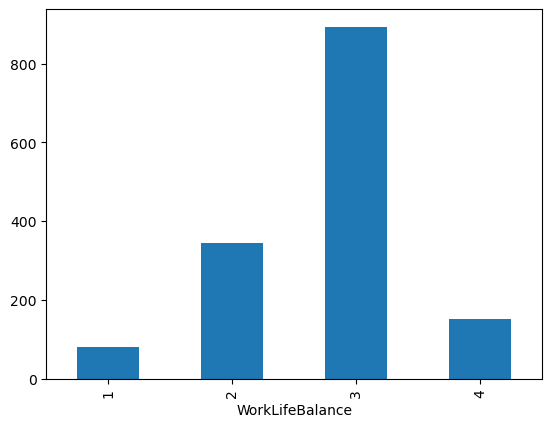

In [131]:
df1["WorkLifeBalance"].value_counts().sort_index().plot(kind="bar")

               mean  median  max
Attrition                       
No         2.781022     3.0    4
Yes        2.658228     3.0    4


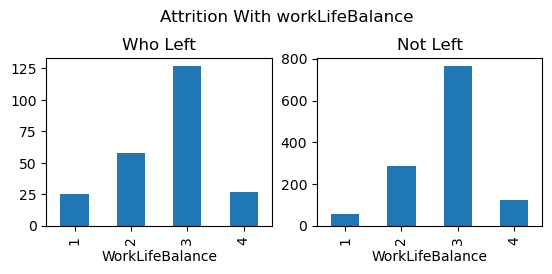

In [132]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["WorkLifeBalance"].value_counts().sort_index().plot(kind="bar")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["WorkLifeBalance"].value_counts().sort_index().plot(kind="bar")
plt.title("Not Left")
plt.suptitle("Attrition With workLifeBalance")

print(df1.groupby("Attrition")["WorkLifeBalance"].agg(["mean","median","max"]))

In [133]:
# Attrirtion With YearAtCompany

In [135]:
df1["YearsAtCompany"].describe()

count    1470.000000
mean        7.008163
std         6.126525
min         0.000000
25%         3.000000
50%         5.000000
75%         9.000000
max        40.000000
Name: YearsAtCompany, dtype: float64

<Axes: ylabel='Frequency'>

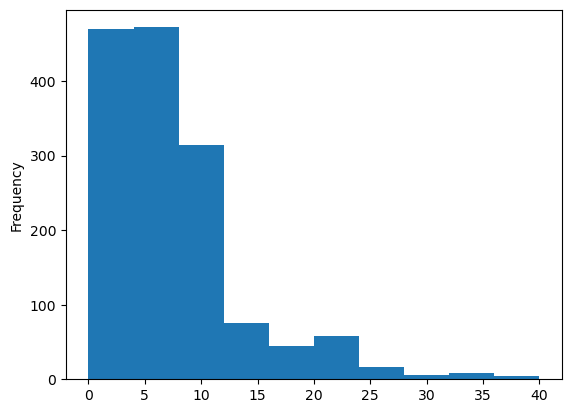

In [137]:
df1["YearsAtCompany"].plot(kind="hist")

               mean  median  max
Attrition                       
No         7.369019     6.0   37
Yes        5.130802     3.0   40


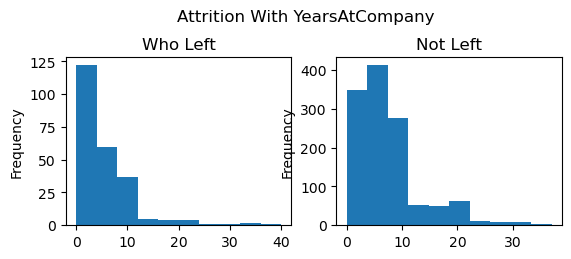

In [139]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["YearsAtCompany"].plot(kind="hist")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["YearsAtCompany"].plot(kind="hist")
plt.title("Not Left")
plt.suptitle("Attrition With YearsAtCompany")

print(df1.groupby("Attrition")["YearsAtCompany"].agg(["mean","median","max"]))

In [140]:
# attrition With YearInCurrentRole

In [144]:
df1["YearsInCurrentRole"].describe()

count    1470.000000
mean        4.229252
std         3.623137
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        18.000000
Name: YearsInCurrentRole, dtype: float64

<Axes: ylabel='Frequency'>

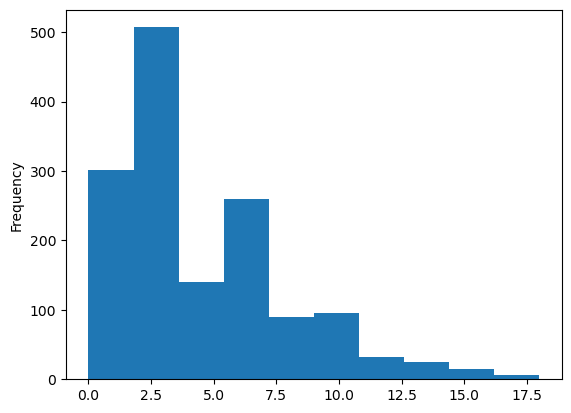

In [145]:
df1["YearsInCurrentRole"].plot(kind="hist")

               mean  median  max
Attrition                       
No         4.484185     3.0   18
Yes        2.902954     2.0   15


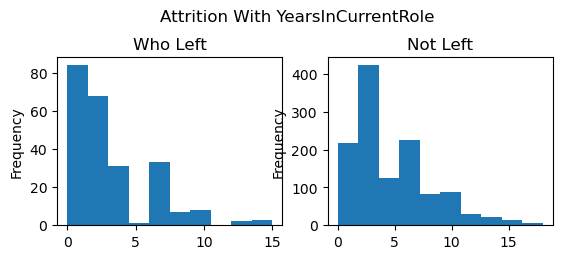

In [146]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["YearsInCurrentRole"].plot(kind="hist")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["YearsInCurrentRole"].plot(kind="hist")
plt.title("Not Left")
plt.suptitle("Attrition With YearsInCurrentRole")

print(df1.groupby("Attrition")["YearsInCurrentRole"].agg(["mean","median","max"]))

In [147]:
# Attriton With YearWithCurrManager

In [148]:
df1["YearsWithCurrManager"].describe()

count    1470.000000
mean        4.123129
std         3.568136
min         0.000000
25%         2.000000
50%         3.000000
75%         7.000000
max        17.000000
Name: YearsWithCurrManager, dtype: float64

<Axes: ylabel='Frequency'>

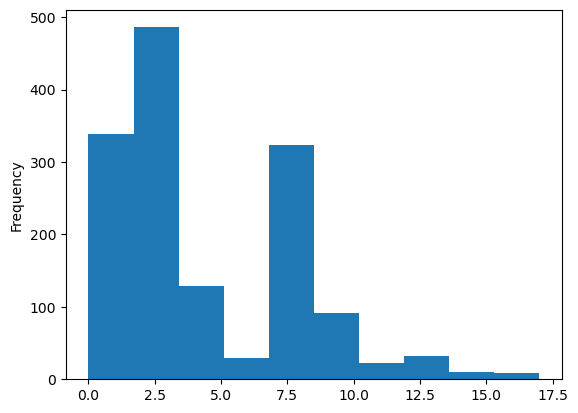

In [150]:
df1["YearsWithCurrManager"].plot(kind="hist")

               mean  median  max
Attrition                       
No         4.367397     3.0   17
Yes        2.852321     2.0   14


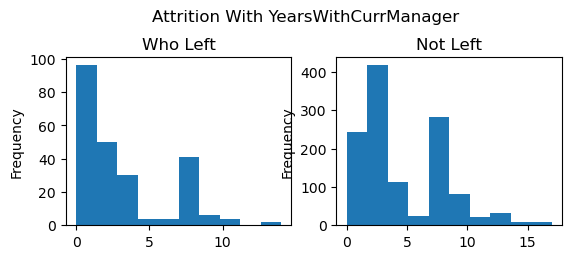

In [151]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["YearsWithCurrManager"].plot(kind="hist")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["YearsWithCurrManager"].plot(kind="hist")
plt.title("Not Left")
plt.suptitle("Attrition With YearsWithCurrManager")

print(df1.groupby("Attrition")["YearsWithCurrManager"].agg(["mean","median","max"]))

In [152]:
# Attrition With DailyrRate

In [153]:
df1["DailyRate"].describe()

count    1470.000000
mean      802.485714
std       403.509100
min       102.000000
25%       465.000000
50%       802.000000
75%      1157.000000
max      1499.000000
Name: DailyRate, dtype: float64

<Axes: ylabel='Frequency'>

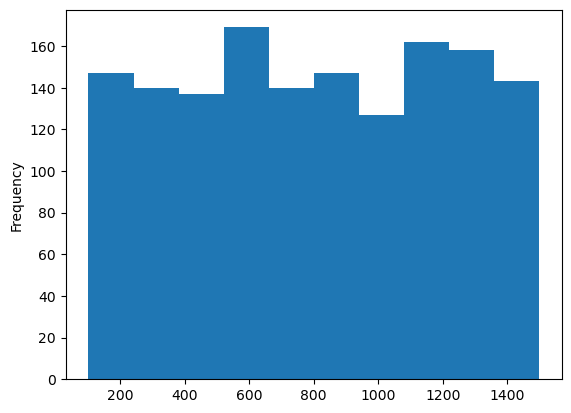

In [155]:
df1["DailyRate"].plot(kind="hist")

                 mean  median   max
Attrition                          
No         812.504461   817.0  1499
Yes        750.362869   699.0  1496


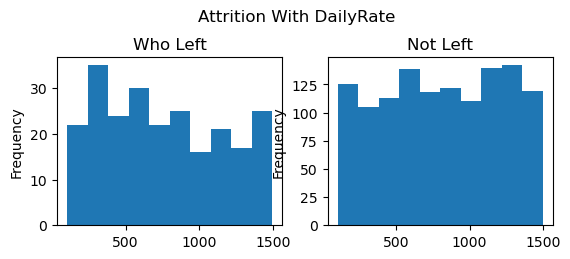

In [157]:
plt.subplot(2,2,1)
df1[df1["Attrition"]=="Yes"]["DailyRate"].plot(kind="hist")
plt.title("Who Left")
plt.subplot(2,2,2)
df1[df1["Attrition"]=="No"]["DailyRate"].plot(kind="hist")
plt.title("Not Left")
plt.suptitle("Attrition With DailyRate")

print(df1.groupby("Attrition")["DailyRate"].agg(["mean","median","max"]))

# category Columns

In [163]:
category

['BusinessTravel',
 'Department',
 'EducationField',
 'JobRole',
 'MaritalStatus',
 'OverTime']

In [164]:
# Attrition With BusinessTravel

<Axes: xlabel='BusinessTravel'>

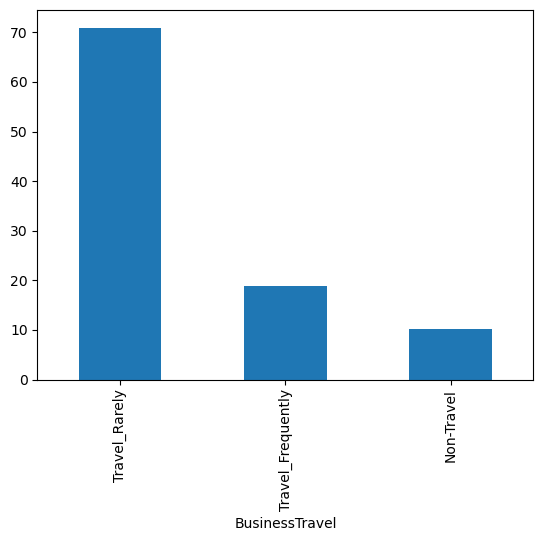

In [167]:
(df1["BusinessTravel"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='BusinessTravel'>

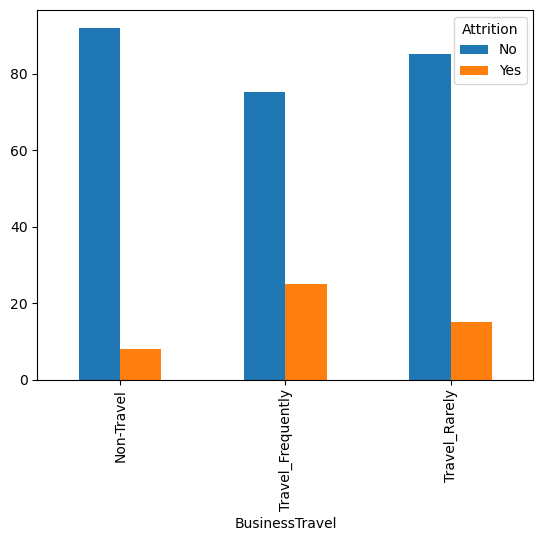

In [170]:
(pd.crosstab(df1["BusinessTravel"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [171]:
# Attrition With Department

<Axes: xlabel='Department'>

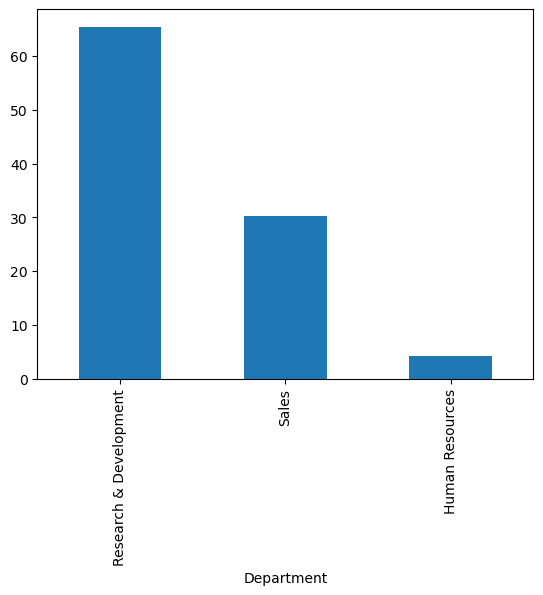

In [173]:
(df1["Department"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='Department'>

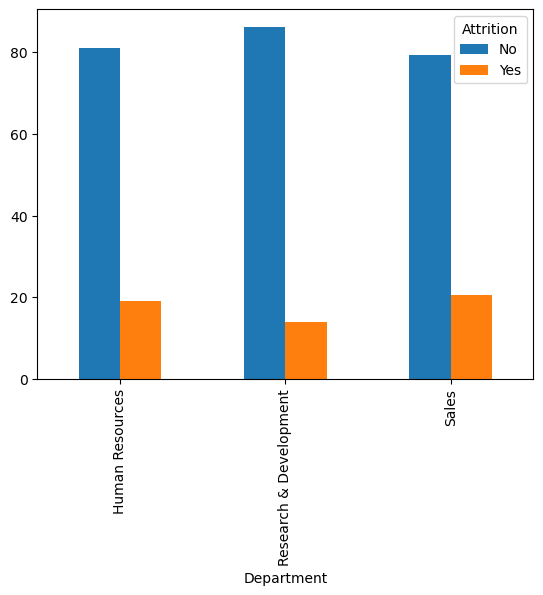

In [176]:
(pd.crosstab(df1["Department"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [177]:
# Attrition With EdicatioFeild

<Axes: xlabel='EducationField'>

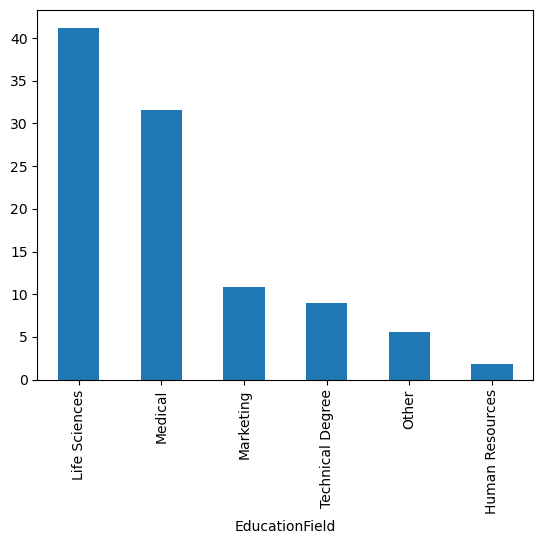

In [179]:
(df1["EducationField"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='EducationField'>

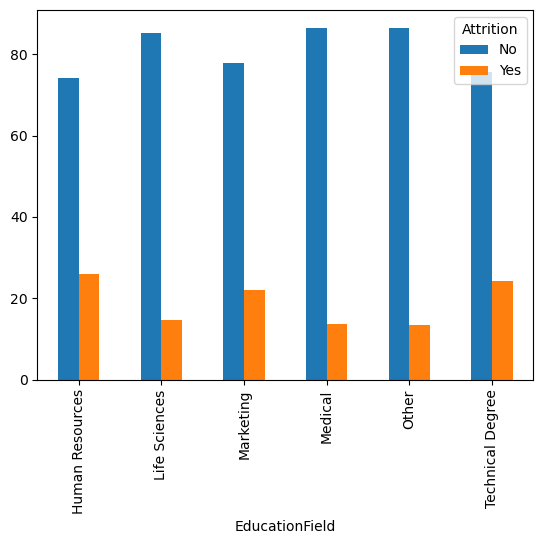

In [181]:
(pd.crosstab(df1["EducationField"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [182]:
# Attrition With jobRole

<Axes: xlabel='JobRole'>

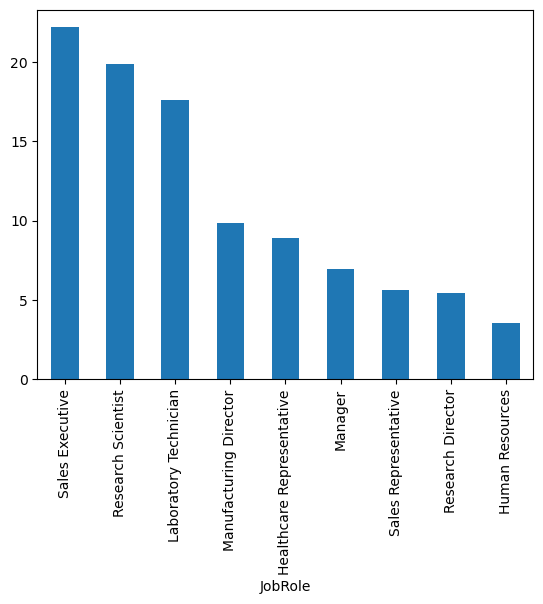

In [186]:
(df1["JobRole"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='JobRole'>

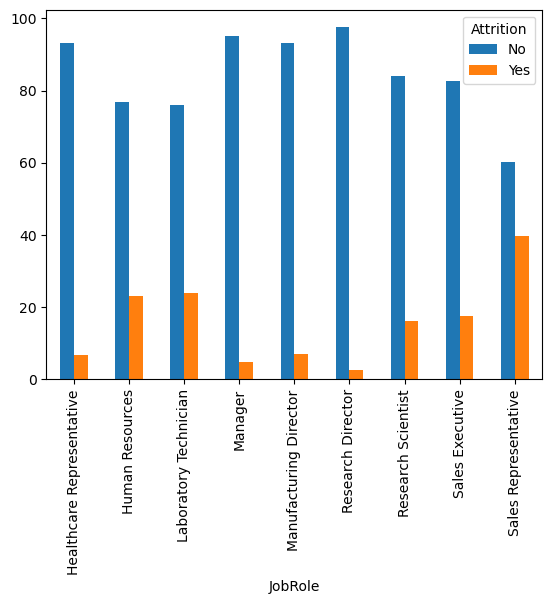

In [191]:
(pd.crosstab(df1["JobRole"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [183]:
# Attrition With MaritailStatus

<Axes: xlabel='MaritalStatus'>

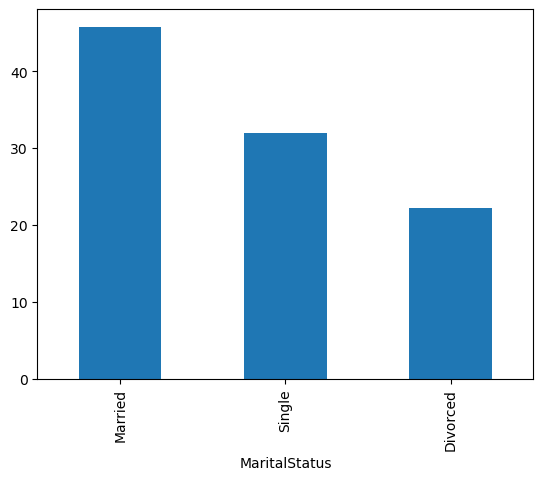

In [187]:
(df1["MaritalStatus"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='MaritalStatus'>

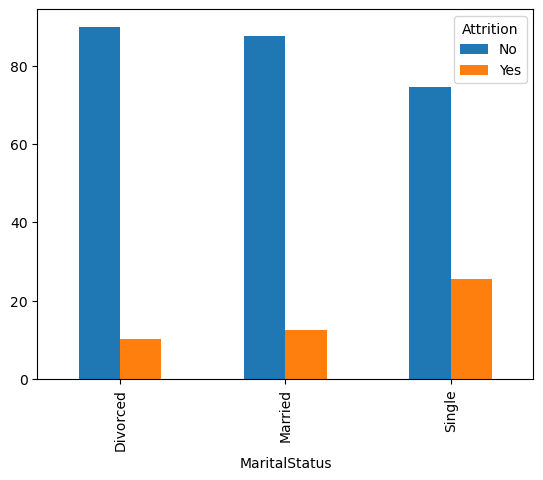

In [194]:
(pd.crosstab(df1["MaritalStatus"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [188]:
# Attrition With Overtime

<Axes: xlabel='OverTime'>

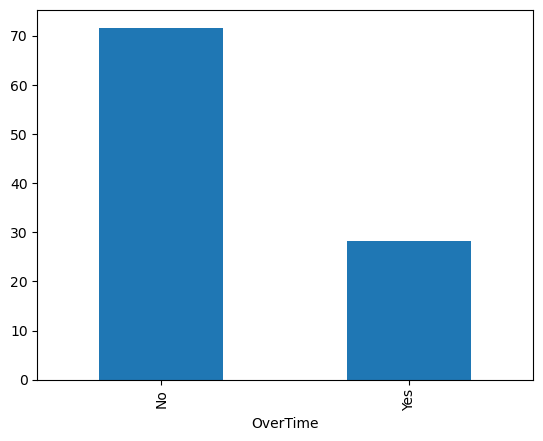

In [189]:
(df1["OverTime"].value_counts(normalize=True)*100).plot(kind="bar")

<Axes: xlabel='OverTime'>

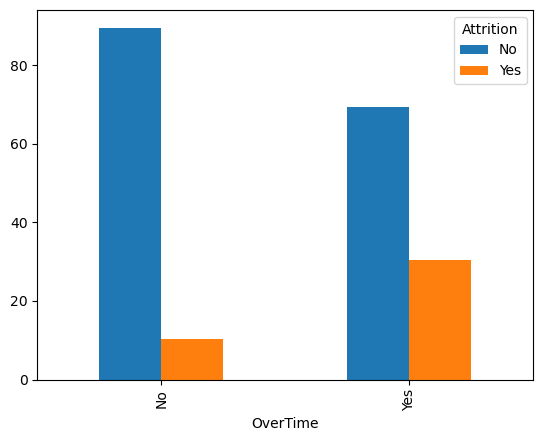

In [193]:
(pd.crosstab(df1["OverTime"],df1["Attrition"],normalize="index")*100).plot(kind="bar")

In [206]:
df1[["Age",'MonthlyIncome']].corr()["Age"][1]

C:\Users\megha\AppData\Local\Temp\ipykernel_16272\4017146142.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df1[["Age",'MonthlyIncome']].corr()["Age"][1]


np.float64(0.4978545669265801)

In [222]:
# moderate & Strong corrleation

In [221]:
d=numaric_import
for i in range(len(numaric_import)):
    for j in range(i + 1, len(numaric_import)):
        
        corr = df1[[d[i], d[j]]].corr()[d[i]][1]
        
        if corr > 0.5 or corr < -0.5:
            print(d[i], d[j], "----", corr)

Age TotalWorkingYears ---- 0.6803805357911985
MonthlyIncome TotalWorkingYears ---- 0.7728932462543574
MonthlyIncome YearsAtCompany ---- 0.5142848257331957
TotalWorkingYears YearsAtCompany ---- 0.6281331552682468
YearsAtCompany YearsInCurrentRole ---- 0.7587537366134619
YearsAtCompany YearsWithCurrManager ---- 0.7692124251007031
YearsInCurrentRole YearsWithCurrManager ---- 0.7143647616385931


<Axes: >

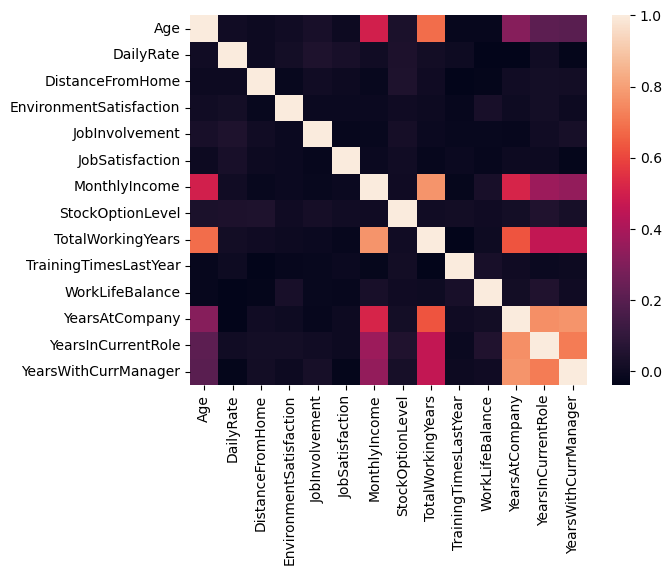

In [223]:
sns.heatmap(df1[numaric_import].corr())